<a href="https://colab.research.google.com/github/ughadeayush767-code/MDM-Machine-Learning/blob/main/Practical_No_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import math
import matplotlib.pyplot as plt

class Layer:
    def __init__(self):
        self.input = None
        self.output = None

    def forward(self, input):
        pass

    def backward(self, output_gradient, learning_rate):
        pass

In [ ]:
class Dense(Layer):
    def __init__(self, input_size, output_size):
        self.weights = np.random.randn(output_size, input_size)
        self.bias = np.random.randn(output_size, 1)

    def forward(self, input):
        self.input = input
        return np.dot(self.weights, self.input) + self.bias

    def backward(self, output_gradient, learning_rate):
        weights_gradient = np.dot(output_gradient, self.input.T)
        input_gradient = np.dot(self.weights.T, output_gradient)
        self.weights -= learning_rate * weights_gradient
        self.bias -= learning_rate * output_gradient
        return input_gradient

In [ ]:
def mse(y_true, y_pred):
    return np.mean(np.power(y_true - y_pred, 2))

def mse_prime(y_true, y_pred):
    return 2 * (y_pred - y_true) / np.size(y_true)

In [ ]:
class Activation(Layer):
    def __init__(self, activation, activation_prime):
        self.activation = activation
        self.activation_prime = activation_prime

    def forward(self, input):
        self.input = input
        return self.activation(self.input)

    def backward(self, output_gradient, learning_rate):
        return np.multiply(output_gradient, self.activation_prime(self.input))


class Tanh(Activation):
    def __init__(self):
        def tanh(x):
            return np.tanh(x)
        def tanh_prime(x):
            return 1 - np.tanh(x) ** 2
        super().__init__(tanh, tanh_prime)


class Sigmoid(Activation):
    def __init__(self):
        def sigmoid(x):
            return 1 / (1 + np.exp(-x))
        def sigmoid_prime(x):
            s = sigmoid(x)
            return s * (1 - s)
        super().__init__(sigmoid, sigmoid_prime)


class Linear(Activation):
    def __init__(self):
        def linear(x):
            return x
        def linear_prime(x):
            return 1
        super().__init__(linear, linear_prime)

In [ ]:
X = np.linspace(-3, 3, 61)
Y = [math.sin(p) for p in X]

network = [
    Dense(1, 10),
    Tanh(),
    Dense(10, 1),
    Linear()
]

epochs = 50
learning_rate = 0.1
errorlist = []

In [ ]:
for e in range(epochs):
    error = 0
    for x, y in zip(X, Y):
        output = np.array([[x]])      # shape (1,1) for Dense

        for layer in network:
            output = layer.forward(output)

        error += mse(y, output)
        grad = mse_prime(y, output)

        for layer in reversed(network):
            grad = layer.backward(grad, learning_rate)

    error /= len(X)
    print(f"{e + 1}/{epochs}, error={error}")
    errorlist.append(error)

1/50, error=0.9539145482488888
2/50, error=0.27343636831571777
3/50, error=0.1550164964101674
4/50, error=0.029933277110649012
5/50, error=0.12309619195625059
6/50, error=0.051042356147033306
7/50, error=0.08366061830890527
8/50, error=0.04805016942516928
9/50, error=0.04880920657359094
10/50, error=0.029901745154828244
11/50, error=0.02593197335586026
12/50, error=0.018814075657766507
13/50, error=0.01758019528332844
14/50, error=0.015225673909233947
15/50, error=0.017674763836974052
16/50, error=0.020069172339941335
17/50, error=0.027539633952548128
18/50, error=0.03397891832392528
19/50, error=0.043488921574058634
20/50, error=0.0506190864637029
21/50, error=0.05813979748549969
22/50, error=0.06257142613832935
23/50, error=0.06579204557925382
24/50, error=0.06668956575551258
25/50, error=0.06661458300997243
26/50, error=0.06583173834248651
27/50, error=0.06543953282057921
28/50, error=0.0654129674435538
29/50, error=0.06421726028478789
30/50, error=0.05948037601429083
31/50, error=0

In [ ]:
actual_Y = []
for x in X:
    output = np.array([[x]])
    for layer in network:
        output = layer.forward(output)
    actual_Y.append(output[0])
    print(output)

[[-0.86765489]]
[[-0.87642961]]
[[-0.88588717]]
[[-0.89607683]]
[[-0.90704558]]
[[-0.91883473]]
[[-0.93147501]]
[[-0.94497908]]
[[-0.95933029]]
[[-0.97446585]]
[[-0.99025159]]
[[-1.006444]]
[[-1.0226337]]
[[-1.03816208]]
[[-1.05200155]]
[[-1.06259118]]
[[-1.06763124]]
[[-1.06387385]]
[[-1.04702511]]
[[-1.01200778]]
[[-0.95396468]]
[[-0.87027242]]
[[-0.76308884]]
[[-0.64068283]]
[[-0.51552001]]
[[-0.39941974]]
[[-0.29908445]]
[[-0.21489259]]
[[-0.14265477]]
[[-0.07622179]]
[[-0.0094842]]
[[0.06249122]]
[[0.14291313]]
[[0.2330555]]
[[0.33228179]]
[[0.43826888]]
[[0.54739327]]
[[0.65522364]]
[[0.75705616]]
[[0.84843023]]
[[0.92556667]]
[[0.98568251]]
[[1.02715664]]
[[1.04954675]]
[[1.05348179]]
[[1.04046801]]
[[1.0126501]]
[[0.97256375]]
[[0.92290661]]
[[0.8663449]]
[[0.80536432]]
[[0.74216734]]
[[0.67861408]]
[[0.6162007]]
[[0.55606738]]
[[0.49902741]]
[[0.44560919]]
[[0.39610426]]
[[0.35061595]]
[[0.30910482]]
[[0.27142874]]


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

In [ ]:
def preprocess_data(x, y, limit):
    x = x.reshape(x.shape[0], 28 * 28, 1)
    x = x.astype("float32") / 255
    y = to_categorical(y)
    y = y.reshape(y.shape[0], 10, 1)
    return x[:limit], y[:limit]

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, y_train = preprocess_data(x_train, y_train, 10000)
x_test, y_test   = preprocess_data(x_test, y_test, 20)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [ ]:
network = [
    Dense(784, 80),
    Sigmoid(),
    Dense(80, 10),
    Sigmoid()
]

epochs = 50
learning_rate = 0.1
errorlist = []

In [ ]:
for e in range(epochs):
    error = 0
    for x, y in zip(x_train, y_train):
        output = x

        for layer in network:
            output = layer.forward(output)

        error += mse(y, output)
        grad = mse_prime(y, output)

        for layer in reversed(network):
            grad = layer.backward(grad, learning_rate)

    error /= len(x_train)
    print(f"{e + 1}/{epochs}, error={error}")
    errorlist.append(error)

1/50, error=0.1017773569395727
2/50, error=0.08482936461880879
3/50, error=0.07938217405268534
4/50, error=0.07681966449035274
5/50, error=0.07544697292567923
6/50, error=0.07425036387862148
7/50, error=0.07301038186896545
8/50, error=0.07194995737371919
9/50, error=0.07100554697199854
10/50, error=0.069157198172652
11/50, error=0.06680074994108579
12/50, error=0.06519352096172167
13/50, error=0.06392424917013022
14/50, error=0.06289835211780259
15/50, error=0.06207665356953084
16/50, error=0.06142190933031374
17/50, error=0.06087432898008884
18/50, error=0.06039665934754053
19/50, error=0.05997446818859594
20/50, error=0.0595992081683817
21/50, error=0.05926129477079171
22/50, error=0.05894952777701777
23/50, error=0.05865366065223643
24/50, error=0.058368444771142
25/50, error=0.05809196757052725
26/50, error=0.057819420867368465
27/50, error=0.05753953591474059
28/50, error=0.05719863105691036
29/50, error=0.056429912236227765
30/50, error=0.05423368906579592
31/50, error=0.05177505

In [ ]:
for e in range(epochs):
    error = 0
    for x, y in zip(x_train, y_train):
        output = x

        for layer in network:
            output = layer.forward(output)

        error += mse(y, output)
        grad = mse_prime(y, output)

        for layer in reversed(network):
            grad = layer.backward(grad, learning_rate)

    error /= len(x_train)
    print(f"{e + 1}/{epochs}, error={error}")
    errorlist.append(error)

1/50, error=0.02346176384245556
2/50, error=0.022448129564581983
3/50, error=0.02179383776069858
4/50, error=0.021303902011591252
5/50, error=0.020911915069706497
6/50, error=0.020581717563409572
7/50, error=0.020293579838776988
8/50, error=0.020035582180481043
9/50, error=0.019800609773514208
10/50, error=0.019584202330616095
11/50, error=0.019383237968009382
12/50, error=0.01919541533380139
13/50, error=0.019018995496838314
14/50, error=0.01885262488865228
15/50, error=0.018695190651379145
16/50, error=0.01854573268166482
17/50, error=0.018403410558384115
18/50, error=0.018267494519074414
19/50, error=0.01813736591411508
20/50, error=0.018012520664708685
21/50, error=0.017892558601548644
22/50, error=0.017777148906707885
23/50, error=0.017665988033864325
24/50, error=0.01755877883940061
25/50, error=0.01745524159358479
26/50, error=0.01735514126931579
27/50, error=0.017258297504515706
28/50, error=0.017164554068200694
29/50, error=0.017073735465470148
30/50, error=0.01698563902014836

In [ ]:
for e in range(epochs):
    error = 0
    for x, y in zip(x_train, y_train):
        output = x

        for layer in network:
            output = layer.forward(output)

        error += mse(y, output)
        grad = mse_prime(y, output)

        for layer in reversed(network):
            grad = layer.backward(grad, learning_rate)

    error /= len(x_train)
    print(f"{e + 1}/{epochs}, error={error}")
    errorlist.append(error)

1/50, error=0.015578222468824754
2/50, error=0.015527421601469565
3/50, error=0.015477692527559088
4/50, error=0.01542897886392985
5/50, error=0.015381222908174678
6/50, error=0.015334367523874556
7/50, error=0.015288359663910048
8/50, error=0.015243155896539698
9/50, error=0.015198728746666756
10/50, error=0.015155069780941272
11/50, error=0.015112184549935929
12/50, error=0.01507007988898025
13/50, error=0.015028751771845077
14/50, error=0.014988181420210054
15/50, error=0.014948339133626845
16/50, error=0.01490919064823093
17/50, error=0.01487070275264375
18/50, error=0.014832847506562871
19/50, error=0.014795604595346032
20/50, error=0.014758960680877724
21/50, error=0.014722905505202234
22/50, error=0.014687426881131307
23/50, error=0.014652507734218705
24/50, error=0.014618126858245125
25/50, error=0.014584262897890084
26/50, error=0.014550899575245364
27/50, error=0.014518029380767504
28/50, error=0.014485653264840625
29/50, error=0.014453775827705576
30/50, error=0.014422398366

In [ ]:
def predict(network, input_data):
    output = input_data
    for layer in network:
        output = layer.forward(output)
    return output

correct = 0

for x, y in zip(x_test, y_test):
    output = predict(network, x)
    if np.argmax(output) == np.argmax(y):
        correct += 1
        print('pred:', np.argmax(output), '\ttrue:', np.argmax(y))
    else:
        print(f'pred: {np.argmax(output)} \ttrue: {np.argmax(y)}  (incorrect)')

accuracy = correct / len(y_test)
print(f"Accuracy: {accuracy}")

pred: 7 	true: 7
pred: 2 	true: 2
pred: 1 	true: 1
pred: 0 	true: 0
pred: 4 	true: 4
pred: 1 	true: 1
pred: 4 	true: 4
pred: 4 	true: 9  (incorrect)
pred: 5 	true: 5
pred: 7 	true: 9  (incorrect)
pred: 0 	true: 0
pred: 8 	true: 6  (incorrect)
pred: 7 	true: 9  (incorrect)
pred: 0 	true: 0
pred: 1 	true: 1
pred: 5 	true: 5
pred: 8 	true: 9  (incorrect)
pred: 7 	true: 7
pred: 3 	true: 3
pred: 4 	true: 4
Accuracy: 0.75


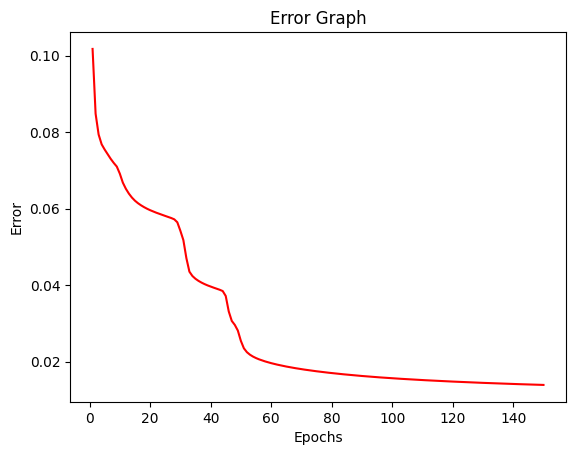

In [ ]:
error = errorlist

X_plot = list(range(1, len(errorlist) + 1))
plt.plot(X_plot, error, color='r')
plt.xlabel("Epochs")
plt.ylabel("Error")
plt.title("Error Graph")
plt.show()